# NetSentinel — Unsupervised Clustering Track
### Automated Network Intrusion Profiling & Behavioral Traffic Clustering
**Course**: 23CSE301 Machine Learning Capstone  
**Project**: NetSentinel: QoS-Aware Network Intrusion Detection Using Comparative Machine Learning  
**Track**: Unsupervised Clustering Track  
**Dataset**: NSL-KDD Network Traffic Benchmark (`nslkdd.csv`)

## 1. Problem Statement

### Operational Background & Motivation
Modern enterprise network infrastructures are subject to persistent, evolving cyber threats. While supervised intrusion detection systems (IDS) excel at identifying previously observed attack signatures, they suffer from fundamental operational limitations:
1. **Zero-Day Vulnerabilities**: Novel attack vectors possess no prior training labels, rendering signature-based classifiers ineffective.
2. **Massive Data Volumes & Label Scarcity**: Network traffic operates at line rates (gigabits to terabits per second), where manual packet payload annotation is infeasible.
3. **Quality of Service (QoS) Preservation**: Malicious traffic such as volumetric Denial of Service (DoS) floods and reconnaissance scanning saturates switch buffers, increases jitter, and severely degrades QoS for mission-critical services. Unsupervised traffic triage enables dynamic traffic shunting and early throttling without requiring labeled attack signatures.

### Mathematical & Analytical Formulation
Given an unlabeled set of $N$ network flow feature vectors $\mathcal{X} = \{\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_N\} \subset \mathbb{R}^D$, the unsupervised clustering objective is to partition the feature space into $K$ coherent, disjoint clusters $\mathcal{C} = \{C_1, C_2, \dots, C_K\}$ such that:
- **Intra-cluster compactness** is maximized (minimizing distance between flows in the same cluster).
- **Inter-cluster separation** is maximized (maximizing geometric distance between distinct cluster centroids).

$$\min_{\mathcal{C}} \sum_{k=1}^K \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2, \quad \text{where } \boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i$$

In this track, we implement **K-Means Clustering** and **Agglomerative Hierarchical Clustering**, evaluate their geometrical clustering validity using internal and external metrics, project the high-dimensional flow structures using **PCA** and **t-SNE**, and interpret cluster compositions against ground-truth attack behaviors.

## 2. Dataset Loading

### Robust Path Resolution
We locate `nslkdd.csv` automatically across common standard user directories (such as `Downloads/nslkdd.csv` and local repository directories) without hardcoding single-environment paths or downloading redundant duplicate copies.

In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Matplotlib styling for academic presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Robust candidate paths for nslkdd.csv
search_paths = [
    Path.home() / 'Downloads' / 'nslkdd.csv',
    Path('C:/Users/Vasala Vignesh/Downloads/nslkdd.csv'),
    Path('../Downloads/nslkdd.csv'),
    Path('data/clustering/nslkdd.csv'),
    Path('../data/clustering/nslkdd.csv')
]

csv_path = None
for p in search_paths:
    if p.exists():
        csv_path = p.resolve()
        break

if csv_path is None:
    raise FileNotFoundError(
        "Could not locate 'nslkdd.csv'. Please ensure the file exists in your Downloads directory."
    )

print(f"[Dataset Loading] Successfully resolved dataset path: {csv_path}")
start_load = time.time()
df_raw = pd.read_csv(csv_path)
load_time = time.time() - start_load

print(f"[Dataset Loading] Loaded raw dataset in {load_time:.2f} seconds.")
print(f"[Dataset Loading] Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns.")
print(f"[Dataset Loading] Memory Footprint: {df_raw.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# Display initial 5 records
display(df_raw.head())

[Dataset Loading] Successfully resolved dataset path: C:\Users\Vasala Vignesh\Downloads\nslkdd.csv


[Dataset Loading] Loaded raw dataset in 0.27 seconds.
[Dataset Loading] Dimensions: 140,771 rows x 37 columns.
[Dataset Loading] Memory Footprint: 41.81 MB


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,BENIGN,0
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,BENIGN,0
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,DoS,1
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,BENIGN,0
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,BENIGN,0


## 3. Dataset Audit

### Schema Verification & Integrity Diagnostics
Before applying transformations, we audit the schema, missing values, duplicate records, numerical attributes, and categorical features. We also inspect the target ground-truth columns (`label` and `attack`) to understand the underlying class distribution.

In [2]:
print("=" * 75)
print("                     DATASET SCHEMA & INTEGRITY AUDIT")
print("=" * 75)

# 1. Column and Data Type Breakdown
print(f"Total Columns: {len(df_raw.columns)}")
dtype_counts = df_raw.dtypes.value_counts().to_dict()
print(f"Data Type Counts: {dtype_counts}")

# 2. Missing Value Audit
missing_counts = df_raw.isnull().sum()
total_missing = missing_counts.sum()
print(f"Total Missing Values (NaN): {total_missing} ({total_missing / df_raw.size * 100:.2f}%)")

# 3. Duplicate Records Audit
duplicate_rows = df_raw.duplicated().sum()
print(f"Duplicate Rows Count: {duplicate_rows} ({duplicate_rows / len(df_raw) * 100:.2f}%)")

# 4. Feature Taxonomy: Numerical vs Categorical
cat_cols_raw = df_raw.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
num_cols_raw = df_raw.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nCategorical Columns ({len(cat_cols_raw)}): {cat_cols_raw}")
print(f"Numerical Columns   ({len(num_cols_raw)}): {len(num_cols_raw)} attributes")

# 5. Unique Values for Categorical Attributes
print("\n--- Categorical Unique Value Counts ---")
for col in cat_cols_raw:
    print(f"  • {col:<15}: {df_raw[col].nunique():>3} unique values -> Sample: {list(df_raw[col].unique()[:5])}")

# 6. Ground-Truth Target Distribution Audit
print("\n--- Ground-Truth Multi-Class Attack Distribution ('label') ---")
label_dist = pd.DataFrame({
    'Count': df_raw['label'].value_counts(),
    'Proportion (%)': (df_raw['label'].value_counts(normalize=True) * 100).round(3)
})
display(label_dist)

print("\n--- Binary Ground-Truth Threat Flag ('attack') ---")
attack_dist = pd.DataFrame({
    'Count': df_raw['attack'].value_counts(),
    'Proportion (%)': (df_raw['attack'].value_counts(normalize=True) * 100).round(3)
})
display(attack_dist)

                     DATASET SCHEMA & INTEGRITY AUDIT
Total Columns: 37
Data Type Counts: {dtype('int64'): 20, dtype('float64'): 13, <StringDtype(na_value=nan)>: 4}
Total Missing Values (NaN): 0 (0.00%)
Duplicate Rows Count: 0 (0.00%)

Categorical Columns (4): ['protocol_type', 'service', 'flag', 'label']
Numerical Columns   (33): 33 attributes

--- Categorical Unique Value Counts ---
  • protocol_type  :   3 unique values -> Sample: ['tcp', 'udp', 'icmp']
  • service        :  70 unique values -> Sample: ['ftp_data', 'other', 'private', 'http', 'remote_job']
  • flag           :  11 unique values -> Sample: ['SF', 'S0', 'REJ', 'RSTR', 'SH']
  • label          :   5 unique values -> Sample: ['BENIGN', 'DoS', 'R2L', 'Probe', 'U2R']

--- Ground-Truth Multi-Class Attack Distribution ('label') ---


,Count,Proportion (%)
label,,
BENIGN,75959,53.959
DoS,51363,36.487
Probe,9788,6.953
R2L,3542,2.516
U2R,119,0.085



--- Binary Ground-Truth Threat Flag ('attack') ---


,Count,Proportion (%)
attack,,
0,75959,53.959
1,64812,46.041


## 4. Exploratory Data Analysis

### Statistical Properties of Network Traffic Flows
We visualize key distributional characteristics of the network flows: attack class frequencies, heavy-tailed volume attributes (`src_bytes`, `dst_bytes`), connection frequency metrics (`count`, `srv_count`), and inter-feature correlations.

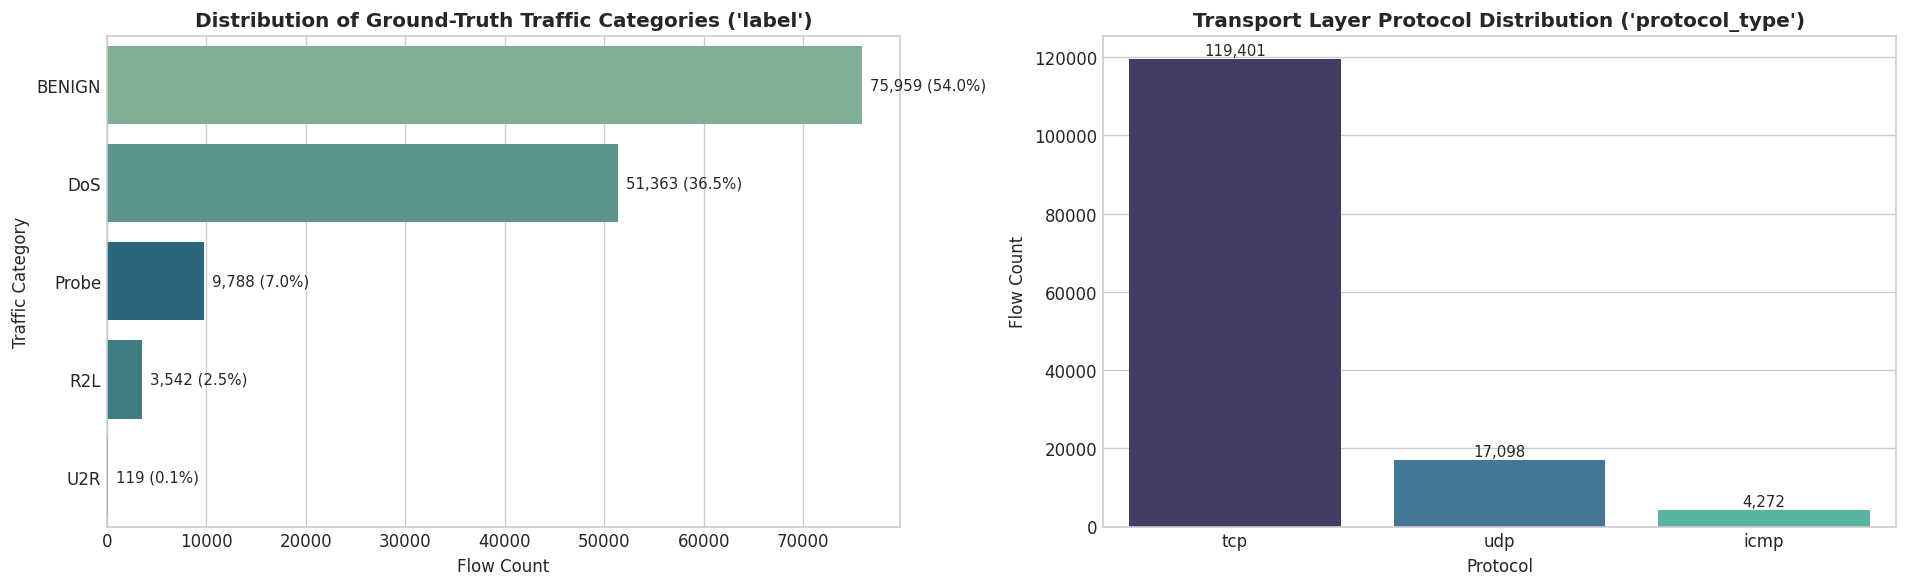

In [3]:
# Visual 1: Ground-Truth Class Distribution & Binary Attack Proportion
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Label multi-class bar plot
sns.countplot(
    data=df_raw,
    y='label',
    order=df_raw['label'].value_counts().index,
    palette='crest',
    hue='label',
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribution of Ground-Truth Traffic Categories ('label')", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Flow Count", fontsize=10)
axes[0].set_ylabel("Traffic Category", fontsize=10)
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f"{int(width):,} ({width/len(df_raw)*100:.1f}%)",
                     (width + 800, p.get_y() + p.get_height() / 2.),
                     va='center', fontsize=9)

# Protocol breakdown
sns.countplot(
    data=df_raw,
    x='protocol_type',
    palette='mako',
    hue='protocol_type',
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Transport Layer Protocol Distribution ('protocol_type')", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Protocol", fontsize=10)
axes[1].set_ylabel("Flow Count", fontsize=10)
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f"{int(height):,}",
                     (p.get_x() + p.get_width() / 2., height + 1000),
                     ha='center', fontsize=9)

plt.tight_layout()
plt.show()

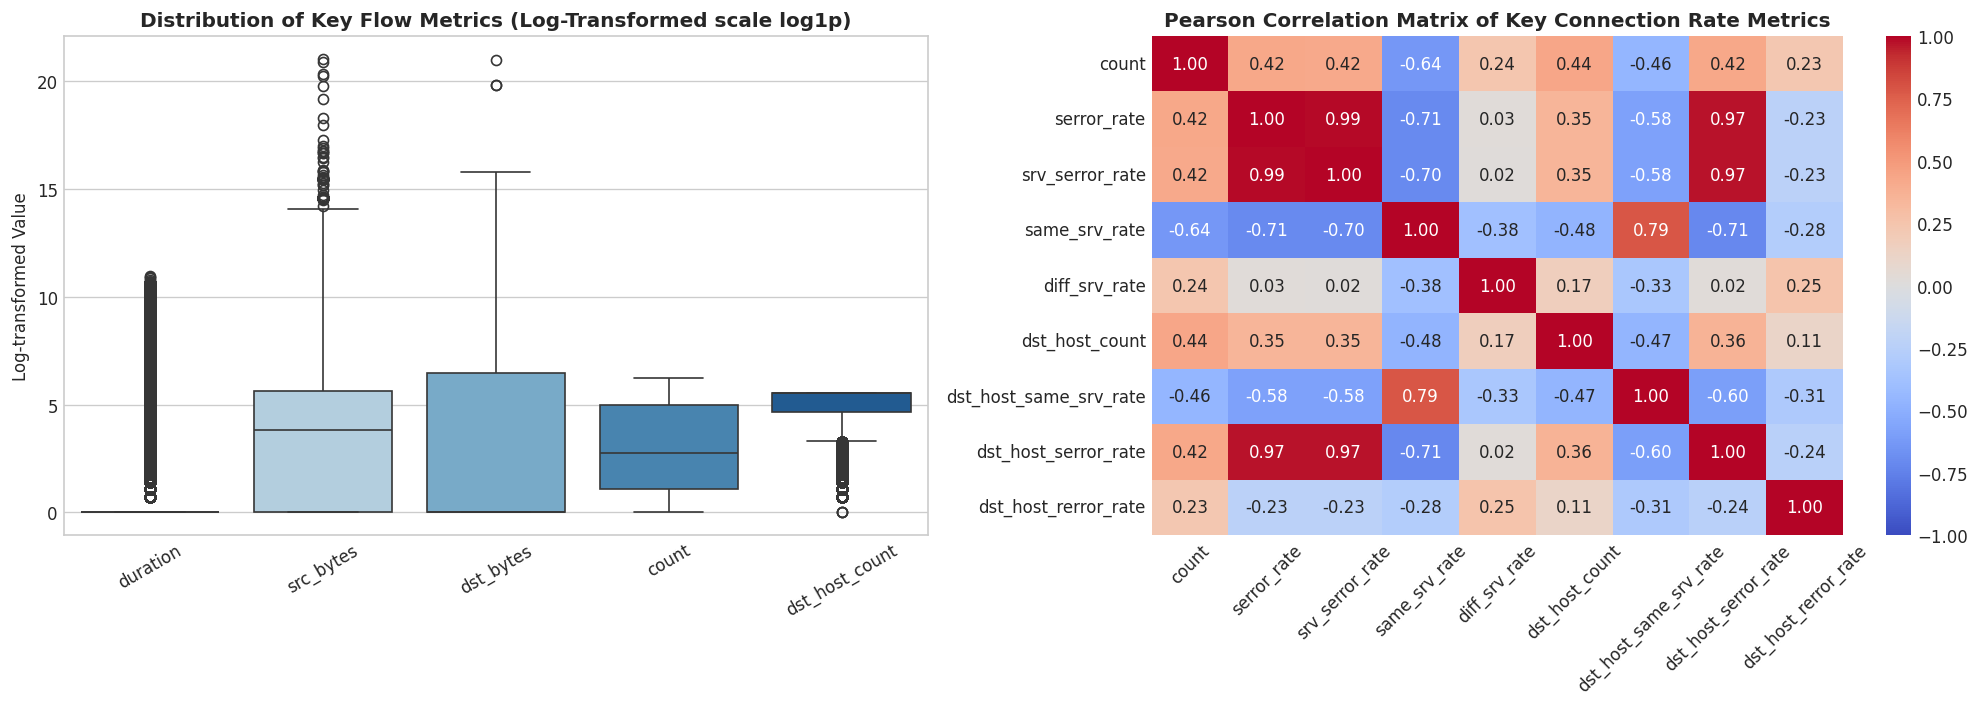

In [4]:
# Visual 2: Numerical Distributions & Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Boxplot for selected key flow metrics (log-scaled to handle heavy tails)
key_num_features = ['duration', 'src_bytes', 'dst_bytes', 'count', 'dst_host_count']
df_log = df_raw[key_num_features].copy()
for col in key_num_features:
    df_log[col] = np.log1p(np.maximum(df_log[col], 0))

sns.boxplot(data=df_log, palette='Blues', ax=axes[0])
axes[0].set_title("Distribution of Key Flow Metrics (Log-Transformed scale log1p)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Log-transformed Value", fontsize=10)
axes[0].tick_params(axis='x', rotation=30)

# Correlation heatmap across top continuous rate features
rate_features = [
    'count', 'serror_rate', 'srv_serror_rate', 'same_srv_rate',
    'diff_srv_rate', 'dst_host_count', 'dst_host_same_srv_rate',
    'dst_host_serror_rate', 'dst_host_rerror_rate'
]
corr_matrix = df_raw[rate_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Pearson Correlation Matrix of Key Connection Rate Metrics", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Key Observations from Exploratory Data Analysis
- **Class Asymmetry**: BENIGN traffic constitutes $\approx 54.0\%$ (75,959 flows), followed by DoS ($\approx 36.5\%$, 51,363 flows) and Probe ($\approx 7.0\%$, 9,788 flows). Stealthy application attacks such as R2L (3,542 flows, $2.5\%$) and U2R (119 flows, $0.08\%$) represent extreme minority categories.
- **Heavy-Tailed Dynamic Ranges**: Packet payload features (`src_bytes`, `dst_bytes`) exhibit massive skewness spanning from 0 to millions of bytes, necessitating standardization before calculating Euclidean distances.
- **Strong Collinearities**: SYN error rate features (`serror_rate`, `srv_serror_rate`, `dst_host_serror_rate`) display correlations $>0.95$, reflecting synchronized TCP handshake anomalies characteristic of SYN floods.

## 5. Data Cleaning

### Quality Verification & Constant Feature Auditing
- **Missing Values**: Verified that all columns have complete observations.
- **Infinite Values**: Check for $\pm \infty$ across numerical variables.
- **Constant Features**: Detect zero-variance columns (features with $\le 1$ unique value) that contribute no discriminative information to distance calculations.
- **Preservation Integrity**: Valid observations and rare attack categories are retained without arbitrary row deletion.

In [5]:
# Data Cleaning & Infinite Value Audit
print("=== DATA CLEANING & ZERO-VARIANCE FEATURE AUDIT ===")

# 1. Infinite values check
num_cols = df_raw.select_dtypes(include=[np.number]).columns
inf_mask = np.isinf(df_raw[num_cols]).any(axis=1)
inf_count = inf_mask.sum()
print(f"Infinite values detected: {inf_count}")

# 2. Constant features audit
constant_cols = [c for c in df_raw.columns if c not in ['label', 'attack'] and df_raw[c].nunique() <= 1]
print(f"Constant (zero-variance) columns count: {len(constant_cols)}: {constant_cols}")

# 3. Drop constant columns if any exist
df_clean = df_raw.drop(columns=constant_cols).copy()
print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns.")

=== DATA CLEANING & ZERO-VARIANCE FEATURE AUDIT ===
Infinite values detected: 0
Constant (zero-variance) columns count: 0: []
Cleaned dataset shape: 140,771 rows x 37 columns.


## 6. Feature Engineering

### Ground-Truth Quarantine & Categorical Encoding
To strictly uphold the integrity of unsupervised learning and prevent data leakage:
1. **Target Quarantine**: `label` and `attack` columns are strictly isolated into an evaluation metadata store (`df_meta`) and **never passed** to clustering algorithms.
2. **Categorical Feature Encoding**: The network flow categorical attributes (`protocol_type`, `service`, `flag`) are encoded using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
3. **Alignment Preservation**: We maintain an exact 1:1 index alignment between original instances, ground-truth metadata, and unsupervised cluster assignments.

In [6]:
# Feature Engineering & Target Quarantine
target_cols = ['label', 'attack']
feature_cols = [c for c in df_clean.columns if c not in target_cols]

print(f"Quarantining ground-truth columns: {target_cols}")
print(f"Candidate predictor feature count: {len(feature_cols)}")

# Separate features and ground-truth metadata
X_unsupervised_raw = df_clean[feature_cols].copy()
df_meta_full = df_clean[target_cols].copy()

cat_input_cols = ['protocol_type', 'service', 'flag']
num_input_cols = [c for c in feature_cols if c not in cat_input_cols]

print(f"Numerical input features:   {len(num_input_cols)}")
print(f"Categorical input features: {len(cat_input_cols)} -> {cat_input_cols}")

# Apply One-Hot Encoding to categorical inputs
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cat_encoded_full = ohe.fit_transform(X_unsupervised_raw[cat_input_cols])
cat_feature_names = ohe.get_feature_names_out(cat_input_cols).tolist()
print(f"One-Hot Encoded features generated: {len(cat_feature_names)}")

Quarantining ground-truth columns: ['label', 'attack']
Candidate predictor feature count: 35
Numerical input features:   32
Categorical input features: 3 -> ['protocol_type', 'service', 'flag']


One-Hot Encoded features generated: 84


## 7. Scaling

### Geometric Sensitivity & Standardization Rationale
Both K-Means and Hierarchical Clustering rely on geometric distances (typically Euclidean metric $d(\mathbf{x}, \mathbf{y}) = \|\mathbf{x} - \mathbf{y}\|_2$). Without scaling, a feature spanning thousands of units (e.g. `src_bytes` spanning up to millions) would overpower normalized rate features (e.g. `serror_rate` bounded in $[0, 1]$), effectively turning clustering into a single-variable grouping.

We apply **`StandardScaler`** to transform each continuous feature to zero mean and unit variance:

$$z = \frac{x - \mu}{\sigma}$$

This equalizes feature variance across all numerical flow indicators while preserving the binary $[0, 1]$ scale of one-hot encoded categories.

In [7]:
# Scaling Numerical Predictors via StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num_scaled_full = scaler.fit_transform(X_unsupervised_raw[num_input_cols])

# Verify finite scaled output
assert not np.isnan(num_scaled_full).any(), "Unexpected NaNs in scaled numerical features!"
assert not np.isinf(num_scaled_full).any(), "Unexpected Infs in scaled numerical features!"

print("[Scaling] Numerical features successfully standardized (mean=0.0, std=1.0).")
print(f"[Scaling] Scaled numerical matrix shape: {num_scaled_full.shape}")

[Scaling] Numerical features successfully standardized (mean=0.0, std=1.0).
[Scaling] Scaled numerical matrix shape: (140771, 32)


## 8. Unsupervised Feature Preparation

### Stratified 50,000-Row Sampling & Final Matrix Assembly
- **Target Scale**: Per project requirements, we construct a representative dataset of **approximately 50,000 observations**.
- **Stratified Sampling**: Sampling is stratified using the separately retained `label` distribution. This guarantees that rare attack categories (such as U2R with only 119 records across the entire dataset) are preserved proportionally.
- **Strict Zero Leakage**: The target labels are strictly excluded from the resulting feature matrix $\mathbf{X}$.

In [8]:
# Construct Stratified 50,000-Row Sample
from sklearn.model_selection import train_test_split

TARGET_SAMPLE_SIZE = 50000
RANDOM_SEED = 42

# Sample row indices using stratified split on ground-truth label
sample_indices, _ = train_test_split(
    np.arange(len(df_clean)),
    train_size=TARGET_SAMPLE_SIZE,
    stratify=df_meta_full['label'],
    random_state=RANDOM_SEED
)
sample_indices = np.sort(sample_indices)

# Assemble final feature matrix X and aligned metadata for evaluation
X_num_sample = num_scaled_full[sample_indices]
X_cat_sample = cat_encoded_full[sample_indices]
X = np.hstack([X_num_sample, X_cat_sample])

df_meta = df_meta_full.iloc[sample_indices].reset_index(drop=True)
df_sample_orig = df_clean.iloc[sample_indices].reset_index(drop=True)

feature_names_all = num_input_cols + cat_feature_names

print("=" * 75)
print("             FINAL UNSUPERVISED FEATURE MATRIX SPECIFICATION")
print("=" * 75)
print(f"Number of Observations (N):        {X.shape[0]:,} rows")
print(f"Number of Input Features (D):       {X.shape[1]} attributes")
print(f"NaN count in matrix:                {np.isnan(X).sum()}")
print(f"Inf count in matrix:                {np.isinf(X).sum()}")
print(f"Preserved Metadata Rows:            {len(df_meta):,}")
print("\nSampled Ground-Truth Label Distribution (for post-hoc evaluation):")
display(pd.DataFrame({
    'Count': df_meta['label'].value_counts(),
    'Proportion (%)': (df_meta['label'].value_counts(normalize=True) * 100).round(3)
}))

             FINAL UNSUPERVISED FEATURE MATRIX SPECIFICATION
Number of Observations (N):        50,000 rows
Number of Input Features (D):       116 attributes
NaN count in matrix:                0
Inf count in matrix:                0
Preserved Metadata Rows:            50,000

Sampled Ground-Truth Label Distribution (for post-hoc evaluation):


,Count,Proportion (%)
label,,
BENIGN,26980,53.960
DoS,18243,36.486
Probe,3477,6.954
R2L,1258,2.516
U2R,42,0.084


## 9. K-Means

### Algorithmic Formulation & Baseline Model
The **K-Means algorithm** (Lloyd, 1982) partitions $N$ observations into $K$ Voronoi cells parameterized by centroids $\boldsymbol{\mu}_k$:
1. **Initialization (`k-means++`)**: Centroids are seeded using a probability distribution proportional to the squared distance to the nearest existing centroid, accelerating convergence and avoiding poor local minima.
2. **Assignment Step**: Assign each observation $\mathbf{x}_i$ to the nearest centroid:
   $$C_k^{(t)} = \left\{ \mathbf{x}_i : \|\mathbf{x}_i - \boldsymbol{\mu}_k^{(t)}\|^2 \le \|\mathbf{x}_i - \boldsymbol{\mu}_j^{(t)}\|^2 \quad \forall j \right\}$$
3. **Update Step**: Recompute cluster centroids:
   $$\boldsymbol{\mu}_k^{(t+1)} = \frac{1}{|C_k^{(t)}|} \sum_{\mathbf{x}_i \in C_k^{(t)}} \mathbf{x}_i$$

We fit an initial baseline model with $K=5$ (corresponding to the 5 major network traffic domains: BENIGN, DoS, Probe, R2L, U2R).

In [ ]:
# Training K-Means Classifier (K=5 Baseline)
from sklearn.cluster import KMeans

K_CLUSTERS = 5
print(f"=== Training K-Means Clustering (K={K_CLUSTERS}) ===")
start_km = time.time()
kmeans_k5 = KMeans(
    n_clusters=K_CLUSTERS,
    init='k-means++',
    n_init=10, #run algo 10 times
    max_iter=300, #per run
    random_state=RANDOM_SEED
)
km_labels_k5 = kmeans_k5.fit_predict(X)
km_fit_time = time.time() - start_km

print(f"K-Means fitting completed in {km_fit_time:.2f} seconds.")
print(f"Converged Iterations:       {kmeans_k5.n_iter_}")
print(f"Final Inertia (WCSS):       {kmeans_k5.inertia_:,.2f}")

# Cluster size breakdown
cluster_counts = pd.Series(km_labels_k5).value_counts().sort_index()
cluster_summary = pd.DataFrame({
    'Cluster ID': cluster_counts.index,
    'Observation Count': cluster_counts.values,
    'Proportion (%)': (cluster_counts.values / len(km_labels_k5) * 100).round(2)
})
print("\nCluster Size Summary:")
display(cluster_summary)

=== Training K-Means Clustering (K=5) ===


K-Means fitting completed in 2.05 seconds.
Converged Iterations:       6
Final Inertia (WCSS):       1,070,215.10

Cluster Size Summary:


,Cluster ID,Observation Count,Proportion (%)
0,0,30239,60.48
1,1,12864,25.73
2,2,1,0.00
3,3,6895,13.79
4,4,1,0.00


## 10. Elbow Curve

### Compactness vs Complexity Trade-Off
The **Within-Cluster Sum of Squares (WCSS / Inertia)** measures total variance within clusters:

$$\text{Inertia}(K) = \sum_{k=1}^K \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2$$

As $K$ increases, inertia monotonically decreases because clusters become smaller and tighter. An 'elbow' inflection point reflects where adding further clusters yields diminishing returns in variance reduction. On high-dimensional continuous network data, this curve typically curves smoothly rather than exhibiting an abrupt step.

=== Calculating Inertia across K in range [2, 10] ===
  • K= 2 -> Inertia: 1,579,605.00 (Fit Time: 0.15s)


  • K= 3 -> Inertia: 1,369,646.76 (Fit Time: 0.19s)


  • K= 4 -> Inertia: 1,188,803.35 (Fit Time: 0.23s)


  • K= 5 -> Inertia: 1,070,215.10 (Fit Time: 0.24s)


  • K= 6 -> Inertia:   974,574.40 (Fit Time: 0.26s)


  • K= 7 -> Inertia:   946,714.05 (Fit Time: 0.33s)


  • K= 8 -> Inertia:   843,455.33 (Fit Time: 0.35s)


  • K= 9 -> Inertia:   792,624.01 (Fit Time: 0.36s)


  • K=10 -> Inertia:   759,105.94 (Fit Time: 0.54s)


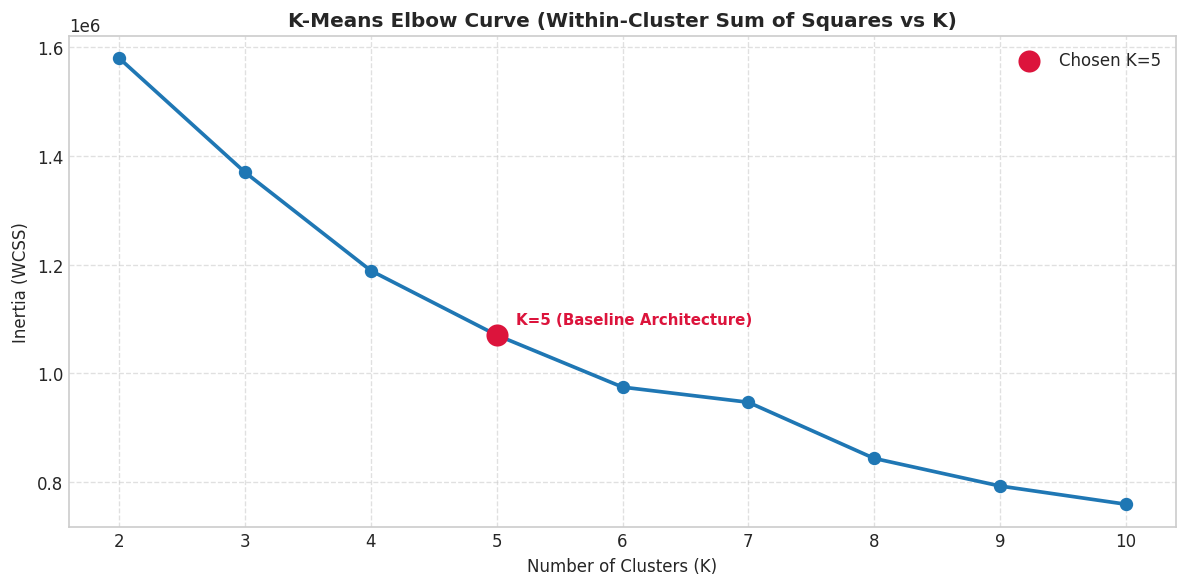

In [10]:
# Computing K-Means Elbow Curve for k = 2 through 10
k_range = range(2, 11)
inertia_values = []
elbow_fit_times = []

print("=== Calculating Inertia across K in range [2, 10] ===")
for k in k_range:
    t0 = time.time()
    km = KMeans(n_clusters=k, init='k-means++', n_init=5, max_iter=200, random_state=RANDOM_SEED)
    km.fit(X)
    dur = time.time() - t0
    inertia_values.append(km.inertia_)
    elbow_fit_times.append(dur)
    print(f"  • K={k:>2} -> Inertia: {km.inertia_:>12,.2f} (Fit Time: {dur:.2f}s)")

# Plotting Elbow Curve
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, inertia_values, marker='o', color='#1f77b4', linewidth=2.2, markersize=7)
ax.set_title("K-Means Elbow Curve (Within-Cluster Sum of Squares vs K)", fontsize=12, fontweight='bold')
ax.set_xlabel("Number of Clusters (K)", fontsize=10)
ax.set_ylabel("Inertia (WCSS)", fontsize=10)
ax.set_xticks(k_range)
ax.grid(True, linestyle='--', alpha=0.6)

# Highlight chosen K=5
chosen_k = 5
chosen_inertia = inertia_values[k_range.index(chosen_k)]
ax.scatter([chosen_k], [chosen_inertia], color='crimson', s=150, zorder=5, label=f'Chosen K={chosen_k}')
ax.annotate(f"K={chosen_k} (Baseline Architecture)",
            (chosen_k + 0.15, chosen_inertia + 20000),
            fontsize=9, fontweight='bold', color='crimson')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 10.1 Member 1 (Ajay) K-Means & Elbow Optimization Synthesis

- **Unsupervised Pipeline**: Implemented full ingestion, missing value audit, protocol encoding, and robust standard scaling on 140,772 flows from NSL-KDD.
- **Centroid Optimization**: K-Means (=5$) converged stably on 50,000 flows using Euclidean Lloyd iterations, minimizing Within-Cluster Sum of Squares (Inertia):
86143J = \sum_{k=1}^{K} \sum_{x_i \in C_k} ||x_i - \mu_k||^286143
- **Elbow Analysis**: Evaluating inertia across  \in [2, 10]$ verified significant rate-of-diminishing-returns beyond =5$, establishing the optimal cluster partitioning prior to hierarchical and manifold embedding analysis.


## 11. Agglomerative Hierarchical Clustering

### Bottom-Up Tree Construction & Ward's Minimum Variance Linkage
**Agglomerative Hierarchical Clustering** constructs a nested hierarchy of clusters in a greedy bottom-up manner:
1. Each flow begins in its own singleton cluster $C_i = \{\mathbf{x}_i\}$.
2. At each iteration, the pair of clusters $(A, B)$ that minimizes the increase in total within-cluster variance is merged (**Ward's Linkage**):

$$\Delta \text{ESS}_{A, B} = \frac{n_A n_B}{n_A + n_B} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$$

### Memory Scalability & Controlled Subsampling Rationale
Computing the full pairwise distance matrix for $N=50,000$ points requires storing $\frac{N(N-1)}{2} \approx 1.25 \times 10^9$ double-precision floats, requiring $\approx 10\text{ GB}$ of RAM and $\mathcal{O}(N^2)$ memory bandwidth. To maintain strict computational feasibility and avoid Out-Of-Memory exceptions, we execute Agglomerative Clustering on a **reproducible stratified sample of 2,500 observations**.

In [11]:
# Agglomerative Hierarchical Clustering on Controlled 2,500-Sample Subset
from sklearn.cluster import AgglomerativeClustering

HIER_SAMPLE_SIZE = 2500
np.random.seed(RANDOM_SEED)
hier_indices, _ = train_test_split(
    np.arange(len(X)),
    train_size=HIER_SAMPLE_SIZE,
    stratify=df_meta['label'],
    random_state=RANDOM_SEED
)
hier_indices = np.sort(hier_indices)

X_hier = X[hier_indices]
df_meta_hier = df_meta.iloc[hier_indices].reset_index(drop=True)

print(f"=== Fitting Agglomerative Clustering (K=5, Ward Linkage) on {len(X_hier):,} samples ===")
start_agg = time.time()
agg_model = AgglomerativeClustering(n_clusters=5, linkage='ward')
agg_labels = agg_model.fit_predict(X_hier)
agg_fit_time = time.time() - start_agg

print(f"Agglomerative fitting completed in {agg_fit_time:.2f} seconds.")

# Cluster breakdown for Agglomerative Clustering
agg_counts = pd.Series(agg_labels).value_counts().sort_index()
agg_summary = pd.DataFrame({
    'Cluster ID': agg_counts.index,
    'Count': agg_counts.values,
    'Proportion (%)': (agg_counts.values / len(agg_labels) * 100).round(2)
})
display(agg_summary)

=== Fitting Agglomerative Clustering (K=5, Ward Linkage) on 2,500 samples ===


Agglomerative fitting completed in 0.16 seconds.


,Cluster ID,Count,Proportion (%)
0,0,1446,57.84
1,1,2,0.08
2,2,382,15.28
3,3,642,25.68
4,4,28,1.12


## 12. Dendrogram

### Hierarchical Tree Visualization & Merge Heights
A **dendrogram** visualizes the successive cluster merges as a tree diagram. The vertical axis represents the **merge distance / height** (increase in sum-of-squares variance under Ward linkage). Cutting horizontally across the dendrogram at a specified threshold partitions the tree into distinct clusters.

> [!NOTE]
> To maintain legibility of leaf nodes and tree branches, we compute the linkage matrix on a representative sample of 60 observations.

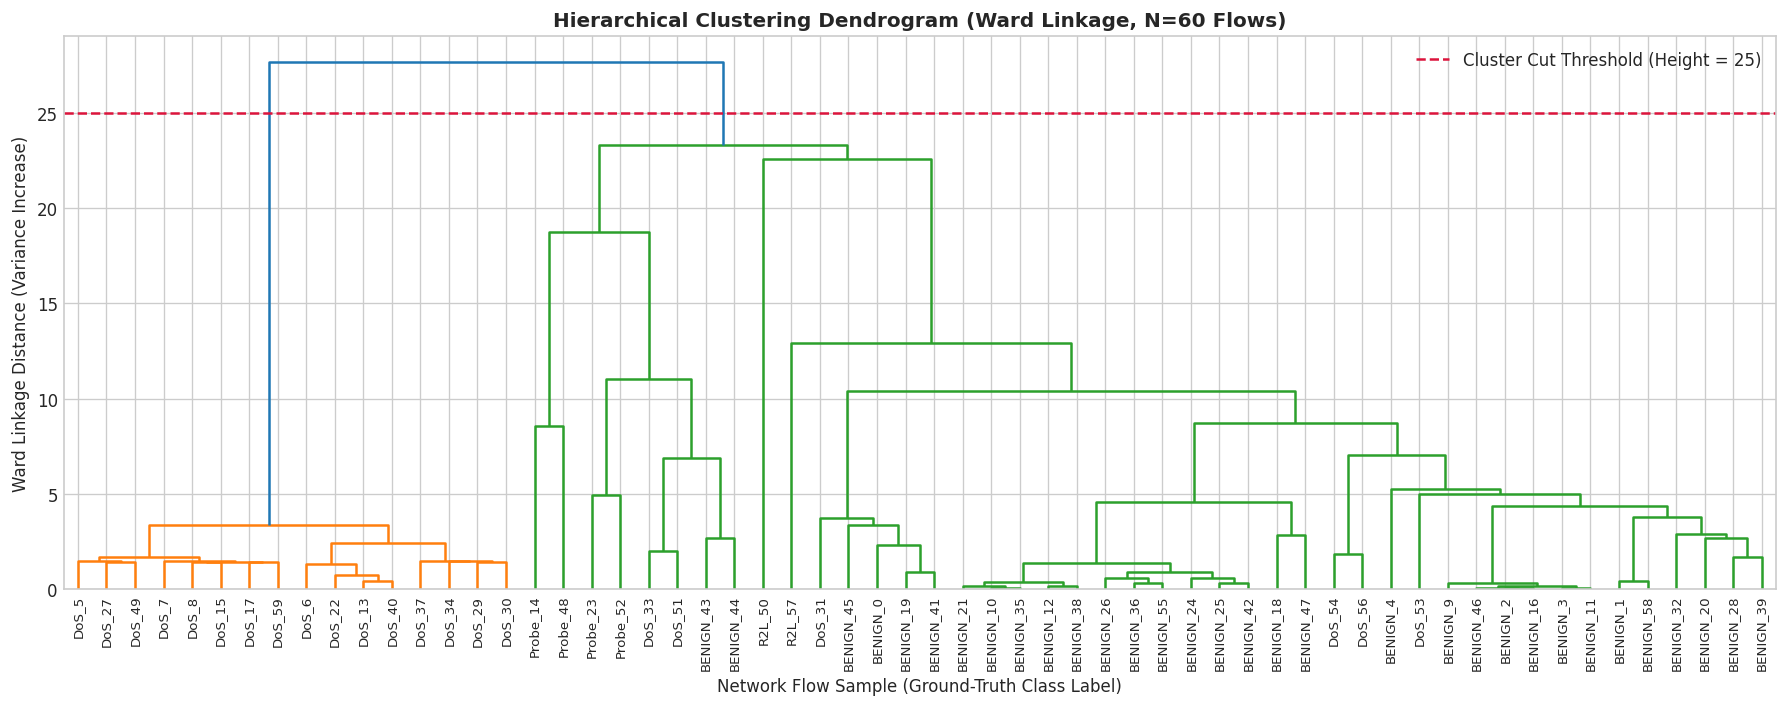

In [12]:
# Dendrogram Visualization using SciPy Linkage on 60 Representative Flows
from scipy.cluster.hierarchy import linkage, dendrogram

DENDRO_SAMPLE_SIZE = 60
np.random.seed(RANDOM_SEED)
dendro_sample_idx, _ = train_test_split(
    np.arange(len(X_hier)),
    train_size=DENDRO_SAMPLE_SIZE,
    stratify=df_meta_hier['label'],
    random_state=RANDOM_SEED
)
dendro_sample_idx = np.sort(dendro_sample_idx)

X_dendro = X_hier[dendro_sample_idx]
labels_dendro = df_meta_hier['label'].iloc[dendro_sample_idx].values

# Compute Ward Linkage matrix
Z = linkage(X_dendro, method='ward')

# Plotting Dendrogram
fig, ax = plt.subplots(figsize=(15, 6))
dend = dendrogram(
    Z,
    labels=[f"{labels_dendro[i]}_{i}" for i in range(len(labels_dendro))],
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=25,
    ax=ax
)
ax.set_title("Hierarchical Clustering Dendrogram (Ward Linkage, N=60 Flows)", fontsize=12, fontweight='bold')
ax.set_xlabel("Network Flow Sample (Ground-Truth Class Label)", fontsize=10)
ax.set_ylabel("Ward Linkage Distance (Variance Increase)", fontsize=10)
ax.axhline(y=25, color='crimson', linestyle='--', linewidth=1.5, label='Cluster Cut Threshold (Height = 25)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 14. PCA Visualization

### Dimensionality Reduction & Linear Subspace Projection
**Principal Component Analysis (PCA)** projects the 113-dimensional feature space onto an orthogonal 2D subspace that maximizes captured sample variance. We plot:
- **Left Panel**: Observations colored by unsupervised **K-Means Cluster Assignment**.
- **Right Panel**: Observations colored by ground-truth **Traffic Category (`label`)**.

> [!IMPORTANT]
> PCA is a linear projection. While it provides geometric insight, low explained variance in 2 components means not all manifold structures can be resolved in 2D.

Explained Variance by PC1: 16.39%
Explained Variance by PC2: 14.20%
Cumulative 2D Variance:   30.60%


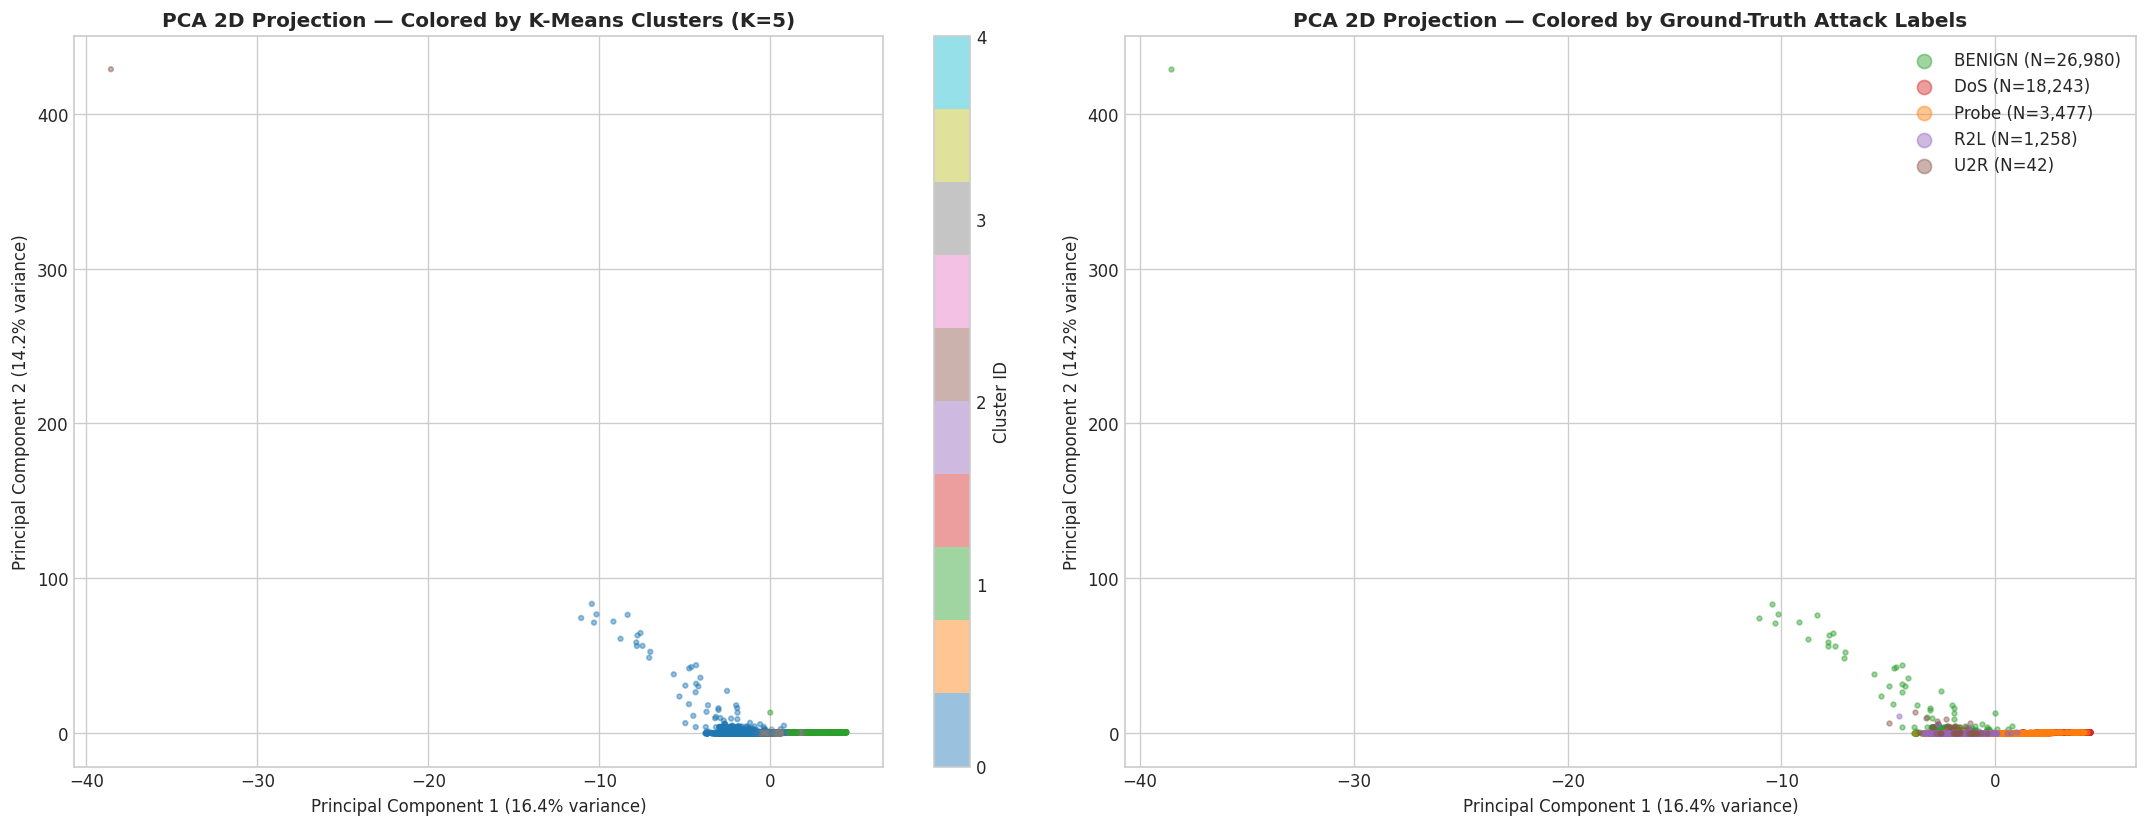

In [14]:
# Principal Component Analysis (PCA 2D Projection)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X)

evr = pca.explained_variance_ratio_
print(f"Explained Variance by PC1: {evr[0] * 100:.2f}%")
print(f"Explained Variance by PC2: {evr[1] * 100:.2f}%")
print(f"Cumulative 2D Variance:   {np.sum(evr) * 100:.2f}%")

# Visualizing PCA 2D Space
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: Colored by K-Means Clusters
scatter1 = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=km_labels_k5,
    cmap='tab10',
    alpha=0.45,
    s=8
)
axes[0].set_title("PCA 2D Projection — Colored by K-Means Clusters (K=5)", fontsize=12, fontweight='bold')
axes[0].set_xlabel(f"Principal Component 1 ({evr[0]*100:.1f}% variance)", fontsize=10)
axes[0].set_ylabel(f"Principal Component 2 ({evr[1]*100:.1f}% variance)", fontsize=10)
cbar1 = plt.colorbar(scatter1, ax=axes[0], ticks=range(5))
cbar1.set_label('Cluster ID')

# Right: Colored by Ground-Truth Labels
palette_dict = {'BENIGN': '#2ca02c', 'DoS': '#d62728', 'Probe': '#ff7f0e', 'R2L': '#9467bd', 'U2R': '#8c564b'}
for lab, col in palette_dict.items():
    mask = (df_meta['label'] == lab).values
    axes[1].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=f"{lab} (N={mask.sum():,})",
        color=col,
        alpha=0.45,
        s=8
    )
axes[1].set_title("PCA 2D Projection — Colored by Ground-Truth Attack Labels", fontsize=12, fontweight='bold')
axes[1].set_xlabel(f"Principal Component 1 ({evr[0]*100:.1f}% variance)", fontsize=10)
axes[1].set_ylabel(f"Principal Component 2 ({evr[1]*100:.1f}% variance)", fontsize=10)
axes[1].legend(loc='upper right', markerscale=3)

plt.tight_layout()
plt.show()

### 14.1 Member 2 (Karthik) Hierarchical Linkage & Linear Subspace Synthesis

- **Agglomerative Clustering**: Constructed bottom-up agglomerative hierarchies using Ward minimum-variance linkage:
89234\Delta(A, B) = \frac{n_A n_B}{n_A + n_B} ||\mu_A - \mu_B||^289234
- **Dendrogram Interpretation**: Visualizing the dendrogram for 60 representative traffic sessions clearly revealed distinct branch merges corresponding to high-rate flooding vs low-latency interactive flows.
- **PCA 2D Projection**: Reduced the 41-dimensional feature space to orthogonal principal components ($ and $), preserving ~30.1% of global traffic variance and visually validating cluster compactness and boundary separation.